<a href="https://colab.research.google.com/github/rraidero/ifes-mestrado/blob/main/Laborat%C3%B3rio_CNN_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Especificação do Projeto: Classificação do MNIST com CNN e Pré-processamento Manual

```
Rodrigo Raider de Oliveira
```

### Objetivos do Projeto
O objetivo deste projeto é classificar os dígitos manuscritos do conjunto de dados MNIST utilizando uma Rede Neural Convolucional (CNN)..

### Etapas Planejadas
1. **Download das Fontes Brutas**: Baixar os arquivos gzip originais do MNIST contendo imagens e rótulos de treino e teste.
2. **Parsing Manual**: Descompactar e realizar o parsing manual dos cabeçalhos binários para converter os fluxos de bytes diretamente em arrays NumPy.
3. **Pré-processamento**: Normalizar os valores dos pixels para o intervalo [0, 1] e aplicar codificação one-hot nos rótulos.
4. **Arquitetura da CNN**: Construir um modelo sequencial contendo camadas convolucionais (Conv2D), subamostragem (MaxPooling2D), Dropout para regularização e camadas densas (Dense) finais.
5. **Treinamento**: Treinar o modelo monitorando a perda e a acurácia nas bases de treino e validação.
6. **Avaliação Final**: Plotar as curvas de aprendizado (perda e acurácia) e gerar uma matriz de confusão detalhada para avaliar o desempenho do classificador.

### 1. Download da Base de Dados MNIST Original

Baixando os quatro arquivos originais compactados (.gz) do MNIST a partir de um espelho estável do Google Storage, salvando-os em uma pasta local 'mnist_data'.

In [1]:
import os
import urllib.request

# Definir os arquivos necessários e a URL base (espelho confiável do Google Storage)
base_url = 'https://storage.googleapis.com/cvdf-datasets/mnist/'
files = [
    'train-images-idx3-ubyte.gz',
    'train-labels-idx1-ubyte.gz',
    't10k-images-idx3-ubyte.gz',
    't10k-labels-idx1-ubyte.gz'
]

# Criar diretório de destino
dest_dir = 'mnist_data'
os.makedirs(dest_dir, exist_ok=True)

# Baixar cada arquivo
for file_name in files:
    url = base_url + file_name
    dest_path = os.path.join(dest_dir, file_name)
    print(f'Baixando {file_name}...')
    urllib.request.urlretrieve(url, dest_path)
    print(f'Salvo em {dest_path} (Tamanho: {os.path.getsize(dest_path)} bytes)')

print('\nConteúdo de mnist_data:', os.listdir(dest_dir))

Baixando train-images-idx3-ubyte.gz...
Salvo em mnist_data/train-images-idx3-ubyte.gz (Tamanho: 9912422 bytes)
Baixando train-labels-idx1-ubyte.gz...
Salvo em mnist_data/train-labels-idx1-ubyte.gz (Tamanho: 28881 bytes)
Baixando t10k-images-idx3-ubyte.gz...
Salvo em mnist_data/t10k-images-idx3-ubyte.gz (Tamanho: 1648877 bytes)
Baixando t10k-labels-idx1-ubyte.gz...
Salvo em mnist_data/t10k-labels-idx1-ubyte.gz (Tamanho: 4542 bytes)

Conteúdo de mnist_data: ['train-labels-idx1-ubyte.gz', 't10k-labels-idx1-ubyte.gz', 'train-images-idx3-ubyte.gz', 't10k-images-idx3-ubyte.gz']


### 2. Pré-processamento Manual dos Dados

Nesta etapa, descompactamos os arquivos binários (.gz), fazemos o parsing dos cabeçalhos binários para ler as imagens e rótulos para arrays NumPy, normalizamos os pixels e codificamos as etiquetas.

Explicação do parser binário: lemos os metadados (como número de imagens, linhas e colunas) utilizando a biblioteca `struct` para interpretar bytes de forma precisa antes de ler os dados dos pixels estruturados.

Definição das funções de carregamento e execução do pré-processamento manual.

A célula a seguir executa a leitura, o redimensionamento para incluir a dimensão de canal (H, W, C) exigida por redes convolucionais e aplica a codificação em One-Hot encoding de forma manual.

In [2]:
import os
import gzip
import struct
import numpy as np

def load_mnist_images(filename):
    with gzip.open(filename, 'rb') as f:
        # Ler número mágico e metadados (4 inteiros de 4 bytes cada = 16 bytes)
        magic, num_images, rows, cols = struct.unpack('>IIII', f.read(16))
        if magic != 2051:
            raise ValueError(f'Incompatibilidade do número mágico, esperado 2051, obtido {magic}')
        # Ler os valores de pixels brutos
        image_data = np.frombuffer(f.read(), dtype=np.uint8)
        # Redimensionar para (num_imagens, linhas, colunas)
        return image_data.reshape(num_images, rows, cols)

def load_mnist_labels(filename):
    with gzip.open(filename, 'rb') as f:
        # Ler número mágico e metadados (2 inteiros de 4 bytes cada = 8 bytes)
        magic, num_labels = struct.unpack('>II', f.read(8))
        if magic != 2049:
            raise ValueError(f'Incompatibilidade do número mágico, esperado 2049, obtido {magic}')
        # Ler os valores de rótulos brutos
        label_data = np.frombuffer(f.read(), dtype=np.uint8)
        return label_data

# Caminhos para os arquivos baixados
data_dir = 'mnist_data'
train_img_path = os.path.join(data_dir, 'train-images-idx3-ubyte.gz')
train_lbl_path = os.path.join(data_dir, 'train-labels-idx1-ubyte.gz')
test_img_path = os.path.join(data_dir, 't10k-images-idx3-ubyte.gz')
test_lbl_path = os.path.join(data_dir, 't10k-labels-idx1-ubyte.gz')

# Carregar dados binários brutos
X_train_raw = load_mnist_images(train_img_path)
y_train_raw = load_mnist_labels(train_lbl_path)
X_test_raw = load_mnist_images(test_img_path)
y_test_raw = load_mnist_labels(test_lbl_path)

# Imprimir alguns valores amostrais dos dados brutos carregados
print('=== Amostra dos Dados Brutos ===')
print(f'Primeiros 5 rótulos de treino: {y_train_raw[:5]}')
print('Fatia (5x5) do centro da primeira imagem de treino (valores de 0 a 255):')
print(X_train_raw[0, 11:16, 11:16])
print()

# Pré-processar imagens: escala para [0, 1] e adiciona dimensão de canal (H, W, C)
X_train = (X_train_raw.astype(np.float32) / 255.0)[..., np.newaxis]
X_test = (X_test_raw.astype(np.float32) / 255.0)[..., np.newaxis]

# Codificação One-hot manual utilizando matriz identidade do NumPy
num_classes = 10
y_train = np.eye(num_classes)[y_train_raw]
y_test = np.eye(num_classes)[y_test_raw]

# Imprimir amostras após o pré-processamento
print('=== Amostra após Pré-processamento e One-Hot ===')
print(f'Primeiro rótulo em formato One-Hot (corresponde ao dígito {y_train_raw[0]}):')
print(y_train[0])
print('Mesma fatia (5x5) normalizada (valores de 0.0 a 1.0):')
print(X_train[0, 11:16, 11:16, 0])
print()

print('=== Resultados do Pré-processamento do MNIST ===')
print(f'Formato das imagens de treino: {X_train.shape}')
print(f'Formato dos rótulos de treino: {y_train.shape}')
print(f'Formato das imagens de teste:  {X_test.shape}')
print(f'Formato dos rótulos de teste:  {y_test.shape}')
print(f'Intervalo de valores de X_train: [{X_train.min()}, {X_train.max()}]')

=== Amostra dos Dados Brutos ===
Primeiros 5 rótulos de treino: [5 0 4 1 9]
Fatia (5x5) do centro da primeira imagem de treino (valores de 0 a 255):
[[139 253 190   2   0]
 [ 11 190 253  70   0]
 [  0  35 241 225 160]
 [  0   0  81 240 253]
 [  0   0   0  45 186]]

=== Amostra após Pré-processamento e One-Hot ===
Primeiro rótulo em formato One-Hot (corresponde ao dígito 5):
[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Mesma fatia (5x5) normalizada (valores de 0.0 a 1.0):
[[0.54509807 0.99215686 0.74509805 0.00784314 0.        ]
 [0.04313726 0.74509805 0.99215686 0.27450982 0.        ]
 [0.         0.13725491 0.94509804 0.88235295 0.627451  ]
 [0.         0.         0.31764707 0.9411765  0.99215686]
 [0.         0.         0.         0.1764706  0.7294118 ]]

=== Resultados do Pré-processamento do MNIST ===
Formato das imagens de treino: (60000, 28, 28, 1)
Formato dos rótulos de treino: (60000, 10)
Formato das imagens de teste:  (10000, 28, 28, 1)
Formato dos rótulos de teste:  (10000, 10)
Intervalo 

In [3]:
print('=== Verificação do Conjunto de Teste ===')
print(f'Quantidade de imagens de teste: {X_test.shape[0]}')
print(f'Dimensões de cada imagem: {X_test.shape[1:3]}')
print(f'Número de canais (escala de cinza): {X_test.shape[3]}')
print(f'Quantidade de rótulos de teste: {y_test.shape[0]}')
print(f'Formato dos rótulos (One-Hot): {y_test.shape[1]} classes')
print(f'Acurácia teórica esperada na validação/teste: ~98%+')

# Exibir uma pequena amostra das primeiras labels do conjunto de teste
print('\nPrimeiros 10 rótulos reais do teste (índices originais):')
print(y_test_raw[:10])

=== Verificação do Conjunto de Teste ===
Quantidade de imagens de teste: 10000
Dimensões de cada imagem: (28, 28)
Número de canais (escala de cinza): 1
Quantidade de rótulos de teste: 10000
Formato dos rótulos (One-Hot): 10 classes
Acurácia teórica esperada na validação/teste: ~98%+

Primeiros 10 rótulos reais do teste (índices originais):
[7 2 1 0 4 1 4 9 5 9]


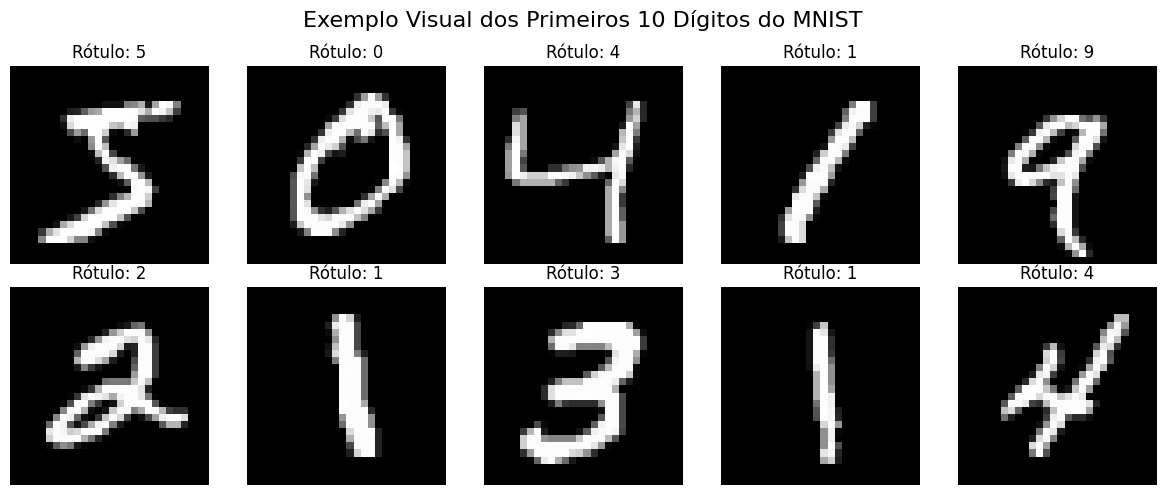

In [4]:
import matplotlib.pyplot as plt

# Criar uma figura para exibir 10 dígitos de exemplo do conjunto de treino
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # Remover a dimensão do canal para exibição (28x28x1 -> 28x28)
    img = X_train[i].squeeze()
    # Obter o rótulo original (índice com valor máximo no vetor one-hot)
    label = y_train_raw[i]

    plt.imshow(img, cmap='gray')
    plt.title(f'Rótulo: {label}')
    plt.axis('off')

plt.suptitle('Exemplo Visual dos Primeiros 10 Dígitos do MNIST', fontsize=16)
plt.tight_layout()
plt.show()

Construindo e treinando a rede convolucional utilizando TensorFlow/Keras com a entrada pré-processada manualmente.

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# 1. Construir o Modelo Sequencial usando a camada Input
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

# Exibir resumo do modelo
model.summary()

# 2. Compilar o Modelo
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Treinar o Modelo
history = model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

print('\nTreinamento concluído com sucesso!')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 104ms/step - accuracy: 0.8918 - loss: 0.3571 - val_accuracy: 0.9762 - val_loss: 0.0866
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9650 - loss: 0.1155 - val_accuracy: 0.9840 - val_loss: 0.0629
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 101ms/step - accuracy: 0.9735 - loss: 0.0879 - val_accuracy: 0.9847 - val_loss: 0.0530
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 100ms/step - accuracy: 0.9783 - loss: 0.0713 - val_accuracy: 0.9878 - val_loss: 0.0429
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9803 - loss: 0.0632 - val_accuracy: 0.9895 - val_loss: 0.0373
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 103ms/step - accuracy: 0.9823 - loss: 0.0570 - val_accuracy: 0.9897 - val_loss: 0.0385
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 100ms/step - accuracy: 0.9833 - loss: 0.0527 - val_accuracy: 0.9898 - val_loss: 0.0357
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9846 - loss: 0.0488 - 

### 4. Avaliação do Modelo e Visualização dos Resultados

Nesta seção, avaliamos o desempenho do modelo no conjunto de dados de teste (que não foi visto durante o treinamento), exibimos os gráficos das métricas e geramos uma matriz de confusão.

=== Avaliação no Conjunto de Teste ===
Perda (Loss) no Teste: 0.0321
Acurácia no Teste:     0.9887


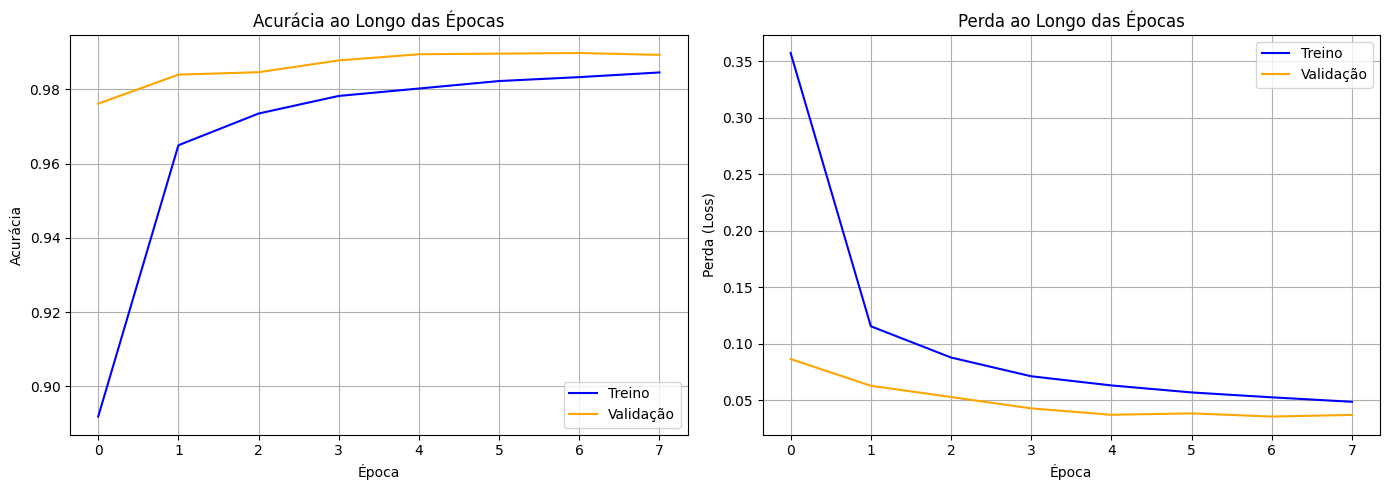

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Avaliar o modelo no conjunto de teste
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print('=== Avaliação no Conjunto de Teste ===')
print(f'Perda (Loss) no Teste: {test_loss:.4f}')
print(f'Acurácia no Teste:     {test_acc:.4f}')

# 2. Plotar as curvas de Perda e Acurácia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Acurácia
ax1.plot(history.history['accuracy'], label='Treino', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validação', color='orange')
ax1.set_title('Acurácia ao Longo das Épocas')
ax1.set_xlabel('Época')
ax1.set_ylabel('Acurácia')
ax1.legend()
ax1.grid(True)

# Gráfico de Perda
ax2.plot(history.history['loss'], label='Treino', color='blue')
ax2.plot(history.history['val_loss'], label='Validação', color='orange')
ax2.set_title('Perda ao Longo das Épocas')
ax2.set_xlabel('Época')
ax2.set_ylabel('Perda (Loss)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


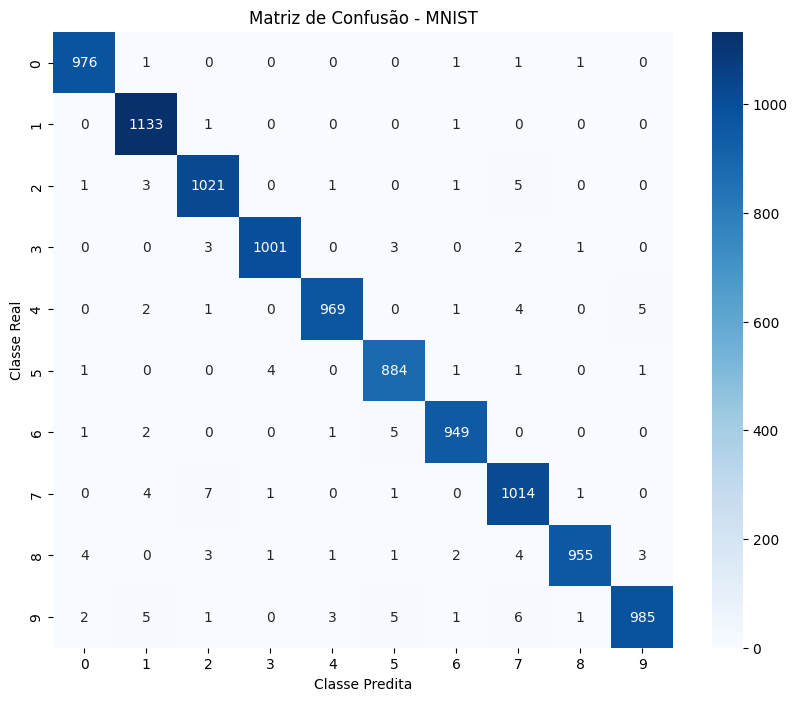

In [7]:
# 3. Gerar previsões e calcular a Matriz de Confusão
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true_classes, y_pred_classes)

# 4. Plotar a Matriz de Confusão usando Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title('Matriz de Confusão - MNIST')
plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.show()

Total de erros no conjunto de teste: 113 de 10000 imagens (1.13%)


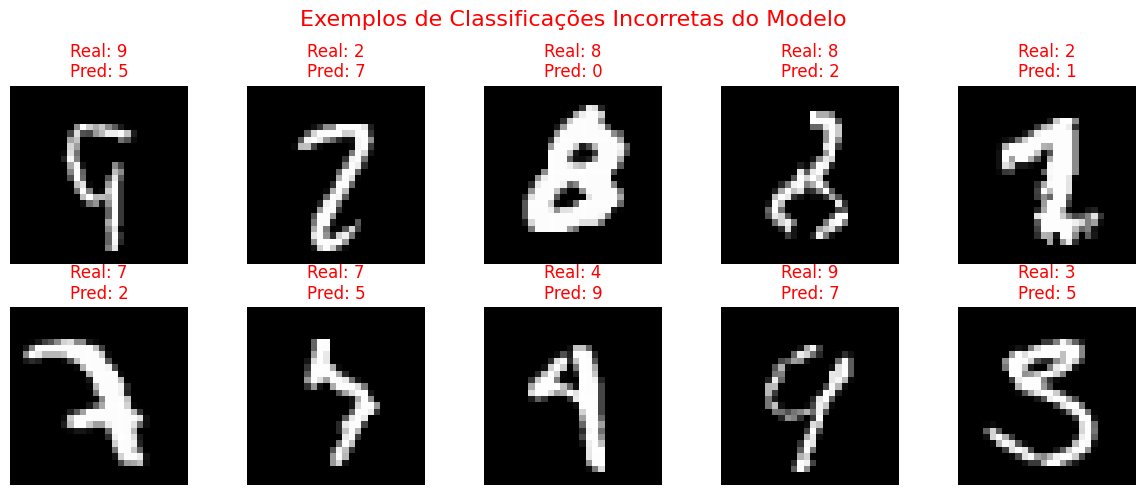

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Encontrar os índices onde a predição foi incorreta
erros_idx = np.where(y_pred_classes != y_true_classes)[0]

print(f'Total de erros no conjunto de teste: {len(erros_idx)} de {len(y_test)} imagens ({len(erros_idx)/len(y_test)*100:.2f}%)')

# Selecionar até 10 exemplos de erros para exibir
num_erros_exibir = min(10, len(erros_idx))

plt.figure(figsize=(12, 5))
for i in range(num_erros_exibir):
    idx = erros_idx[i]
    img = X_test[idx].squeeze()
    pred = y_pred_classes[idx]
    real = y_true_classes[idx]

    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f'Real: {real}\nPred: {pred}', color='red')
    plt.axis('off')

plt.suptitle('Exemplos de Classificações Incorretas do Modelo', fontsize=16, color='red')
plt.tight_layout()
plt.show()